# Compare RefEdit-Bench Text and Mixed ViEScore

Compare saved per-sample `modified_viescore.jsonl` outputs for the `text` and `mixed` inference runs. Rows are paired by `sample_id`; the notebook validates that paired rows have matching instructions and categories. It reports SC, PQ, and O independently (there is no combined score here), lists cases where text is better on at least one metric, and visualizes selected cases with the source, mixed visual-prompt annotation, text output, and mixed output. Expand each case's text and mixed agent trace to inspect every observation, thought, action, and execution result.

By default, each mode uses its latest run. Set `MMEDIT_REFEDIT_BENCH_TEXT_RUN` or `MMEDIT_REFEDIT_BENCH_MIXED_RUN` to a specific `run_<timestamp>` name to compare selected runs. The cells read saved scores and generated images only; they do not run inference or VIEScore.

In [5]:
import json
import os
from pathlib import Path
from statistics import fmean

import matplotlib.pyplot as plt
from IPython.display import display
from PIL import Image

from evaluation.notebook import load_benchmark, resolve_run_directory

BENCHMARK = "refedit_bench"
METRICS = ("sc", "pq", "o")
TOLERANCE = 1e-9
MAX_CASES_TO_VISUALIZE = None  # Set to None to visualize every text-winning case.

text_context = load_benchmark(BENCHMARK, prompt_mode="text")
mixed_context = load_benchmark(BENCHMARK, prompt_mode="mixed")
TEXT_OUTPUT_ROOT = text_context.output_dir
MIXED_OUTPUT_ROOT = mixed_context.output_dir
records = text_context.records
image_loader = text_context.image_loader
text_run_name = os.environ.get("MMEDIT_REFEDIT_BENCH_TEXT_RUN") or None
mixed_run_name = os.environ.get("MMEDIT_REFEDIT_BENCH_MIXED_RUN") or None
TEXT_RUN_DIR = resolve_run_directory(TEXT_OUTPUT_ROOT, text_run_name)
MIXED_RUN_DIR = resolve_run_directory(MIXED_OUTPUT_ROOT, mixed_run_name)

print("Text run:", TEXT_RUN_DIR)
print("Mixed run:", MIXED_RUN_DIR)

Text run: /Users/nghialt3670/Projects/MMEdit/mmedit-framework/.out/evaluation/refedit_bench/text/run_20261011_163954_808537
Mixed run: /Users/nghialt3670/Projects/MMEdit/mmedit-framework/.out/evaluation/refedit_bench/mixed/run_20261011_230935_381218


In [6]:
def read_score_rows(run_dir, expected_mode):
    score_path = run_dir / "metrics" / "modified_viescore.jsonl"
    if not score_path.is_file():
        raise FileNotFoundError(f"Saved ViEScore output not found: {score_path}")
    rows = [json.loads(line) for line in score_path.read_text(encoding="utf-8").splitlines() if line.strip()]
    indexed = {}
    for row in rows:
        sample_id = row.get("sample_id")
        if not isinstance(sample_id, str) or not sample_id:
            raise ValueError(f"Missing sample_id in {score_path}")
        if sample_id in indexed:
            raise ValueError(f"Duplicate sample_id {sample_id!r} in {score_path}")
        if row.get("prompt_mode") != expected_mode:
            raise ValueError(
                f"Expected {expected_mode!r} scores in {score_path}, "
                f"got {row.get('prompt_mode')!r} for {sample_id!r}"
            )
        for metric in METRICS:
            if metric not in row:
                raise ValueError(f"Missing {metric!r} score for {sample_id!r} in {score_path}")
        indexed[sample_id] = row
    return indexed


text_scores = read_score_rows(TEXT_RUN_DIR, "text")
mixed_scores = read_score_rows(MIXED_RUN_DIR, "mixed")
paired_ids = sorted(text_scores.keys() & mixed_scores.keys())
text_only_ids = sorted(text_scores.keys() - mixed_scores.keys())
mixed_only_ids = sorted(mixed_scores.keys() - text_scores.keys())
if not paired_ids:
    raise ValueError("The selected text and mixed runs have no paired sample IDs.")

comparison_rows = []
for sample_id in paired_ids:
    text_row = text_scores[sample_id]
    mixed_row = mixed_scores[sample_id]
    if text_row.get("instruction") != mixed_row.get("instruction"):
        raise ValueError(f"Instruction mismatch for paired sample {sample_id!r}")
    if text_row.get("category") != mixed_row.get("category"):
        raise ValueError(f"Category mismatch for paired sample {sample_id!r}")
    deltas = {metric: float(text_row[metric]) - float(mixed_row[metric]) for metric in METRICS}
    text_wins = [metric for metric, delta in deltas.items() if delta > TOLERANCE]
    mixed_wins = [metric for metric, delta in deltas.items() if delta < -TOLERANCE]
    comparison_rows.append(
        {
            "sample_id": sample_id,
            "annotation_index": text_row.get("annotation_index"),
            "category": text_row["category"],
            "instruction": text_row["instruction"],
            "text_scores": {metric: float(text_row[metric]) for metric in METRICS},
            "mixed_scores": {metric: float(mixed_row[metric]) for metric in METRICS},
            "delta_text_minus_mixed": deltas,
            "text_wins": text_wins,
            "mixed_wins": mixed_wins,
            "text_wins_all_metrics": len(text_wins) == len(METRICS),
            "text_output_path": Path(text_row["output_path"]),
            "mixed_output_path": Path(mixed_row["output_path"]),
        }
    )

text_better_cases = [row for row in comparison_rows if row["text_wins"]]
text_all_metrics_cases = [row for row in text_better_cases if row["text_wins_all_metrics"]]
summary = {
    "paired samples": len(paired_ids),
    "text-only samples": len(text_only_ids),
    "mixed-only samples": len(mixed_only_ids),
    "text better on at least one metric": len(text_better_cases),
    "text better on all three metrics": len(text_all_metrics_cases),
}
for metric in METRICS:
    deltas = [row["delta_text_minus_mixed"][metric] for row in comparison_rows]
    summary[f"{metric.upper()} mean (text)"] = fmean(row["text_scores"][metric] for row in comparison_rows)
    summary[f"{metric.upper()} mean (mixed)"] = fmean(row["mixed_scores"][metric] for row in comparison_rows)
    summary[f"{metric.upper()} text wins / ties / losses"] = (
        sum(delta > TOLERANCE for delta in deltas),
        sum(abs(delta) <= TOLERANCE for delta in deltas),
        sum(delta < -TOLERANCE for delta in deltas),
    )

display([{"measure": key, "value": value} for key, value in summary.items()])
print("\nText-outperforming cases are selected when text scores higher on at least one of SC, PQ, or O.")
print("Unpaired text sample IDs:", text_only_ids)
print("Unpaired mixed sample IDs:", mixed_only_ids)

[{'measure': 'paired samples', 'value': 200},
 {'measure': 'text-only samples', 'value': 0},
 {'measure': 'mixed-only samples', 'value': 0},
 {'measure': 'text better on at least one metric', 'value': 102},
 {'measure': 'text better on all three metrics', 'value': 21},
 {'measure': 'SC mean (text)', 'value': 7.385},
 {'measure': 'SC mean (mixed)', 'value': 7.31},
 {'measure': 'SC text wins / ties / losses', 'value': (58, 91, 51)},
 {'measure': 'PQ mean (text)', 'value': 4.375},
 {'measure': 'PQ mean (mixed)', 'value': 4.345},
 {'measure': 'PQ text wins / ties / losses', 'value': (65, 71, 64)},
 {'measure': 'O mean (text)', 'value': 5.048083651936735},
 {'measure': 'O mean (mixed)', 'value': 5.0745252928112246},
 {'measure': 'O text wins / ties / losses', 'value': (78, 36, 86)}]


Text-outperforming cases are selected when text scores higher on at least one of SC, PQ, or O.
Unpaired text sample IDs: []
Unpaired mixed sample IDs: []


In [7]:
ranked_text_better_cases = sorted(
    text_better_cases,
    key=lambda row: (
        row["text_wins_all_metrics"],
        len(row["text_wins"]),
        sum(max(delta, 0.0) for delta in row["delta_text_minus_mixed"].values()),
    ),
    reverse=True,
)
case_table = [
    {
        "sample_id": row["sample_id"],
        "category": row["category"],
        "text_wins": ", ".join(metric.upper() for metric in row["text_wins"]),
        "all_metrics": row["text_wins_all_metrics"],
        **{
            f"{metric.upper()} text": row["text_scores"][metric]
            for metric in METRICS
        },
        **{
            f"{metric.upper()} mixed": row["mixed_scores"][metric]
            for metric in METRICS
        },
        **{
            f"{metric.upper()} Δ": row["delta_text_minus_mixed"][metric]
            for metric in METRICS
        },
        "instruction": row["instruction"],
    }
    for row in ranked_text_better_cases
]
display(case_table)

if not ranked_text_better_cases:
    print("No paired cases have a higher text score on SC, PQ, or O.")
else:
    visualization_cases = ranked_text_better_cases
    if MAX_CASES_TO_VISUALIZE is not None:
        visualization_cases = visualization_cases[:MAX_CASES_TO_VISUALIZE]
    print(
        f"Visualizing {len(visualization_cases)} of {len(ranked_text_better_cases)} "
        "text-outperforming cases."
    )

[{'sample_id': 'hard:101',
  'category': 'hard',
  'text_wins': 'SC, PQ, O',
  'all_metrics': True,
  'SC text': 10.0,
  'PQ text': 8.0,
  'O text': 8.94427190999916,
  'SC mixed': 0.0,
  'PQ mixed': 1.0,
  'O mixed': 0.0,
  'SC Δ': 10.0,
  'PQ Δ': 7.0,
  'O Δ': 8.94427190999916,
  'instruction': 'Remove the large belt buckle of the lady.'},
 {'sample_id': 'hard:123',
  'category': 'hard',
  'text_wins': 'SC, PQ, O',
  'all_metrics': True,
  'SC text': 8.0,
  'PQ text': 6.0,
  'O text': 6.928203230275509,
  'SC mixed': 0.0,
  'PQ mixed': 2.0,
  'O mixed': 0.0,
  'SC Δ': 8.0,
  'PQ Δ': 4.0,
  'O Δ': 6.928203230275509,
  'instruction': 'Let the zebra be a small baby zebra.'},
 {'sample_id': 'hard:190',
  'category': 'hard',
  'text_wins': 'SC, PQ, O',
  'all_metrics': True,
  'SC text': 9.0,
  'PQ text': 5.0,
  'O text': 6.708203932499369,
  'SC mixed': 0.0,
  'PQ mixed': 3.0,
  'O mixed': 0.0,
  'SC Δ': 9.0,
  'PQ Δ': 2.0,
  'O Δ': 6.708203932499369,
  'instruction': 'Change the screen 

Visualizing 102 of 102 text-outperforming cases.


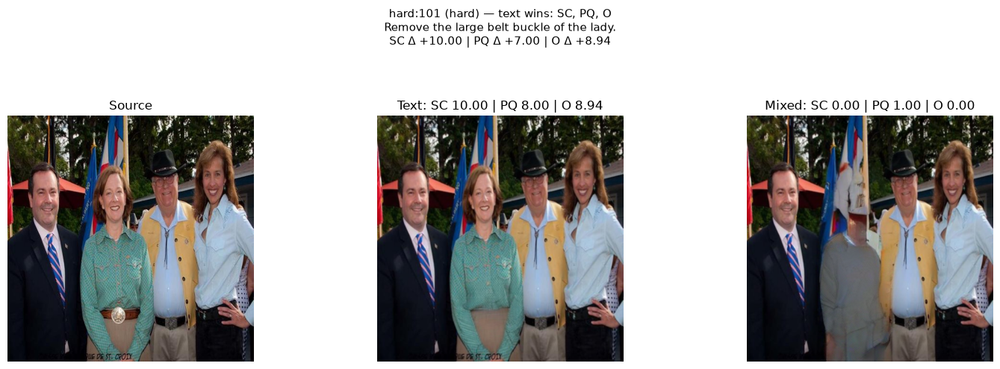

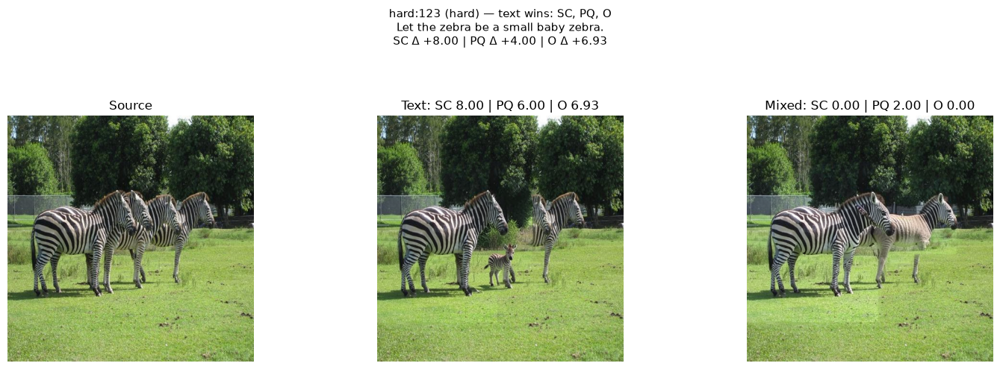

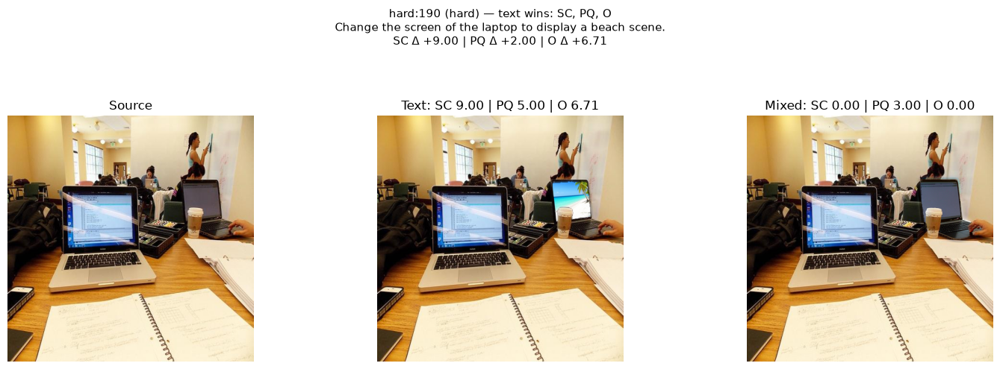

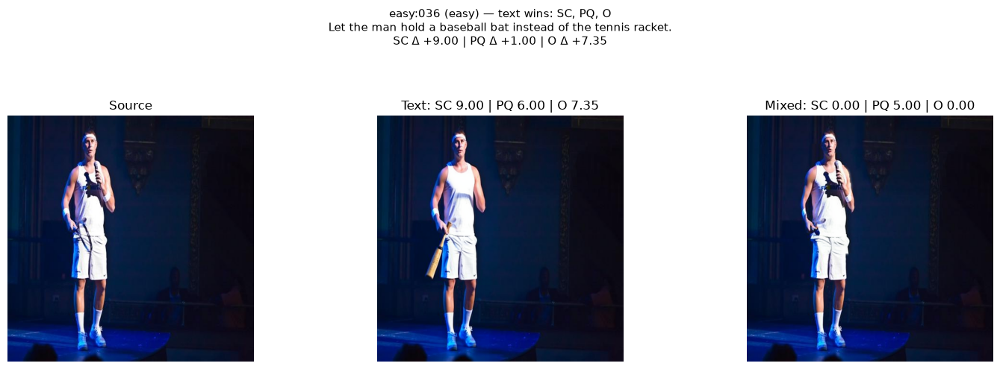

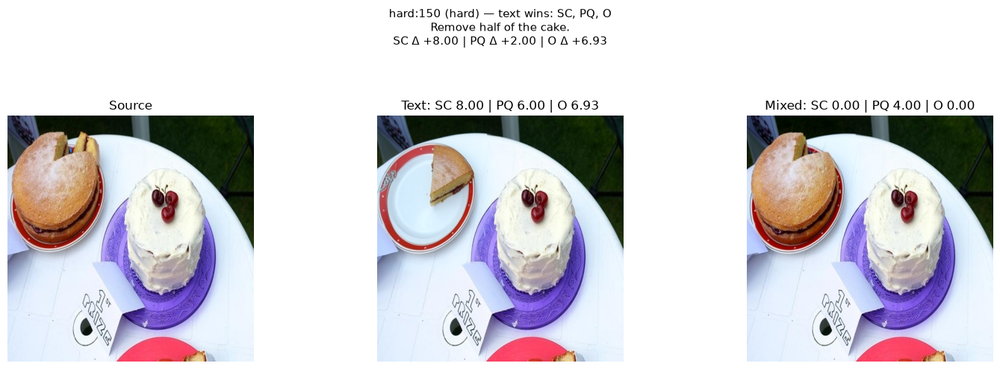

...

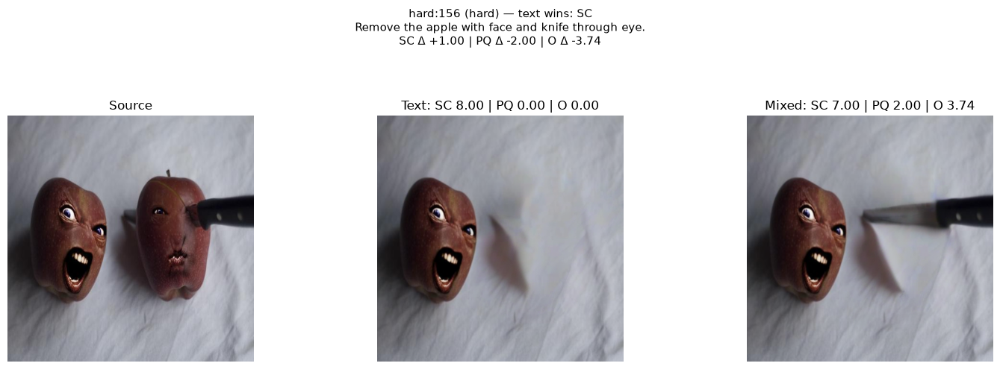

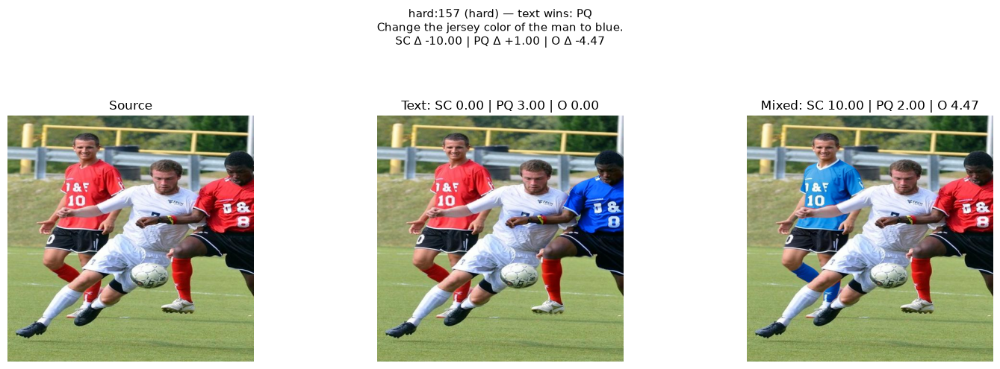

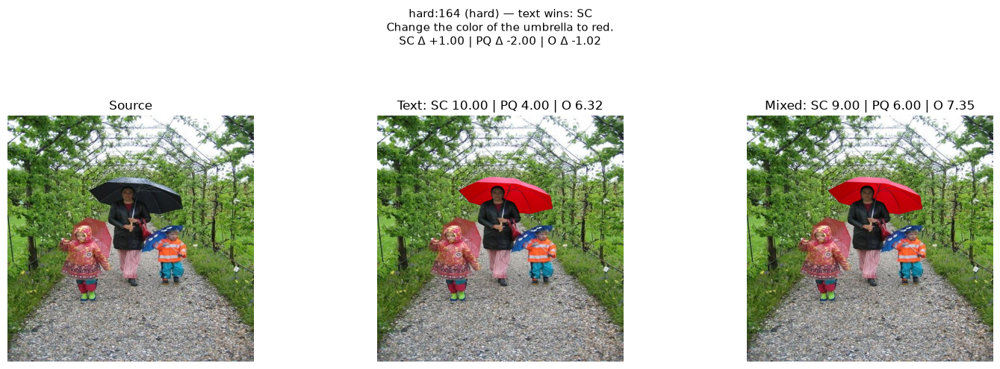

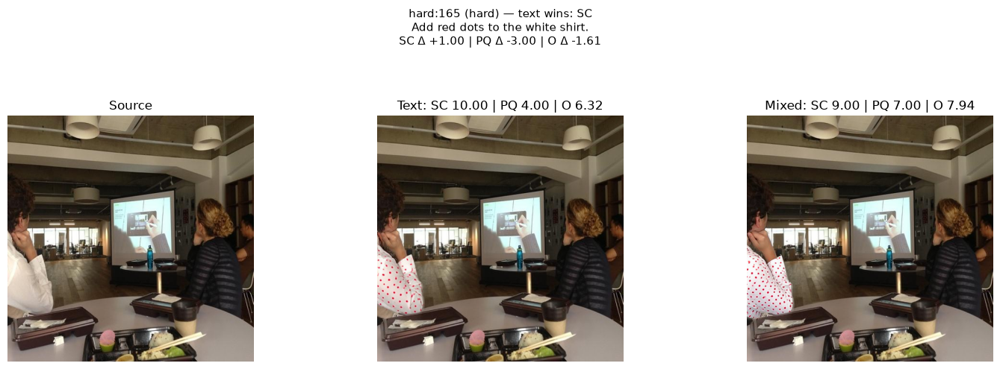

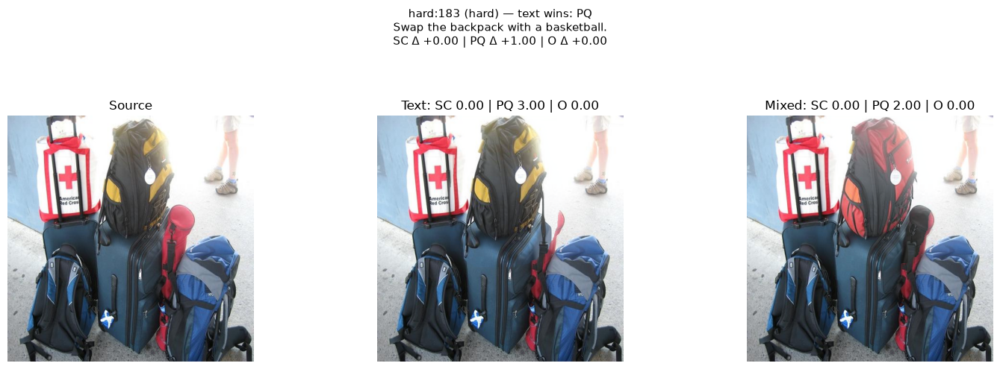

In [8]:
from html import escape

from IPython.display import Markdown


def load_agent_trajectory(run_dir, output_path):
    file_stem = output_path.stem.removesuffix("_output")
    raw_path = run_dir / "logs" / file_stem / "raw.json"
    if not raw_path.is_file():
        raise FileNotFoundError(f"Agent trace not found: {raw_path}")
    raw = json.loads(raw_path.read_text(encoding="utf-8"))
    trajectory = raw.get("agent_trajectory")
    if not isinstance(trajectory, list):
        raise ValueError(f"Missing agent_trajectory in {raw_path}")
    return trajectory


def display_agent_trajectory(run_dir, output_path, label):
    trajectory = load_agent_trajectory(run_dir, output_path)
    sections = [f"<details><summary>{escape(label)} agent trace ({len(trajectory)} steps)</summary>"]
    for step_number, step in enumerate(trajectory, start=1):
        sections.append(f"<h4>Step {step_number}</h4>")
        for field, heading in (("observation", "Observation"), ("thought", "Thought"), ("act", "Action")):
            if field not in step:
                continue
            value = step[field]
            if isinstance(value, (dict, list)):
                text = json.dumps(value, ensure_ascii=False, indent=2, default=str)
            else:
                text = str(value)
            sections.append(f"<b>{heading}</b><pre>{escape(text)}</pre>")
    sections.append("</details>")
    display(Markdown("\n".join(sections)))


record_by_sample_id = {record["sample_id"]: record for record in records}
source_image_cache = {}

for row in visualization_cases:
    sample_id = row["sample_id"]
    record = record_by_sample_id.get(sample_id)
    if record is None:
        raise KeyError(f"No benchmark annotation found for {sample_id!r}")
    if sample_id not in source_image_cache:
        reference = image_loader.parse_reference(record.get("source_ref"))
        if reference is None:
            raise ValueError(f"No source image reference for {sample_id!r}")
        dataset_id, split, row_index, image_field = reference
        source_row = image_loader.get_row(dataset_id, split, row_index)
        source_image_cache[sample_id] = image_loader.as_image(
            source_row[image_field]
        ).convert("RGB")
    source_image = source_image_cache[sample_id]

    text_output_path = row["text_output_path"]
    mixed_output_path = row["mixed_output_path"]
    annotated_path = mixed_output_path.with_name(
        mixed_output_path.name.removesuffix("_output.png") + "_annotated.png"
    )
    if not annotated_path.is_file():
        raise FileNotFoundError(f"Mixed visual-prompt annotation not found: {annotated_path}")
    with Image.open(annotated_path) as image:
        mixed_annotated_image = image.convert("RGB").copy()
    with Image.open(text_output_path) as image:
        text_image = image.convert("RGB").copy()
    with Image.open(mixed_output_path) as image:
        mixed_image = image.convert("RGB").copy()

    figure, axes = plt.subplots(1, 4, figsize=(20, 5))
    panels = (
        (source_image, "Source"),
        (mixed_annotated_image, "Mixed visual prompts"),
        (
            text_image,
            "Text: " + " | ".join(f"{metric.upper()} {row['text_scores'][metric]:.2f}" for metric in METRICS),
        ),
        (
            mixed_image,
            "Mixed: " + " | ".join(f"{metric.upper()} {row['mixed_scores'][metric]:.2f}" for metric in METRICS),
        ),
    )
    for axis, (image, title) in zip(axes, panels, strict=True):
        axis.imshow(image)
        axis.set_title(title)
        axis.axis("off")
    deltas = row["delta_text_minus_mixed"]
    delta_text = " | ".join(f"{metric.upper()} Δ {deltas[metric]:+.2f}" for metric in METRICS)
    figure.suptitle(
        f"{sample_id} ({row['category']}) — text wins: "
        f"{', '.join(metric.upper() for metric in row['text_wins'])}\n"
        f"{row['instruction']}\n{delta_text}",
        fontsize=11,
    )
    figure.tight_layout(rect=(0, 0, 1, 0.86))
    display(figure)
    plt.close(figure)

    display_agent_trajectory(TEXT_RUN_DIR, text_output_path, "Text")
    display_agent_trajectory(MIXED_RUN_DIR, mixed_output_path, "Mixed")